# End-to-End Retail Analytics: Sales, Customer & Product Insights

## Project Overview

This project performs end-to-end retail analytics using real-world transaction data from an online retailer.

The analysis focuses on:
- Understanding and cleaning transaction data
- Analyzing sales and revenue trends
- Identifying top-performing products
- Analyzing customer purchasing behaviour
- Comparing sales across countries
- Segmenting customers based on purchasing behaviour
- Generating actionable business insights and recommendations

## Business Objective

The objective is to use transaction-level retail data to identify patterns in sales, products, customers, and purchasing behaviour that can support better business decisions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

%matplotlib inline

In [2]:
df = pd.read_excel("Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print("Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 5268


In [4]:
print("Cancelled transactions:", df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Negative quantities:", (df["Quantity"] < 0).sum())

print("Zero or negative prices:", (df["UnitPrice"] <= 0).sum())

print("Missing descriptions:", df["Description"].isnull().sum())

Cancelled transactions: 9288
Negative quantities: 10624
Zero or negative prices: 2517
Missing descriptions: 1454


In [5]:
# Remove duplicate rows
df = df.drop_duplicates()

# Remove cancelled invoices
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# Keep only positive quantities
df = df[df["Quantity"] > 0]

# Keep only positive unit prices
df = df[df["UnitPrice"] > 0]

# Remove rows with missing product descriptions
df = df.dropna(subset=["Description"])

print("Shape after cleaning:", df.shape)
print("Remaining missing values:")
print(df.isnull().sum())

Shape after cleaning: (524878, 8)
Remaining missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
dtype: int64


In [6]:
df["TotalSales"] = df["Quantity"] * df["UnitPrice"]

print("Total Sales Revenue:", f"£{df['TotalSales'].sum():,.2f}")
print("Number of Transactions:", df["InvoiceNo"].nunique())
print("Number of Products:", df["StockCode"].nunique())
print("Number of Countries:", df["Country"].nunique())

Total Sales Revenue: £10,642,110.80
Number of Transactions: 19960
Number of Products: 3922
Number of Countries: 38


In [7]:
unique_customers = df["CustomerID"].nunique()
total_quantity = df["Quantity"].sum()
average_order_value = df.groupby("InvoiceNo")["TotalSales"].sum().mean()

print("Unique Customers:", unique_customers)
print("Total Units Sold:", f"{total_quantity:,}")
print("Average Order Value:", f"£{average_order_value:,.2f}")

Unique Customers: 4338
Total Units Sold: 5,572,420
Average Order Value: £533.17


In [8]:
# Create a monthly sales summary
monthly_sales = (
    df.set_index("InvoiceDate")
      .resample("ME")["TotalSales"]
      .sum()
)

print("Monthly Sales Revenue:")
print(monthly_sales)

Monthly Sales Revenue:
InvoiceDate
2010-12-31     821452.730
2011-01-31     689811.610
2011-02-28     522545.560
2011-03-31     716215.260
2011-04-30     536968.491
2011-05-31     769296.610
2011-06-30     760547.010
2011-07-31     718076.121
2011-08-31     757841.380
2011-09-30    1056435.192
2011-10-31    1151263.730
2011-11-30    1503866.780
2011-12-31     637790.330
Freq: ME, Name: TotalSales, dtype: float64


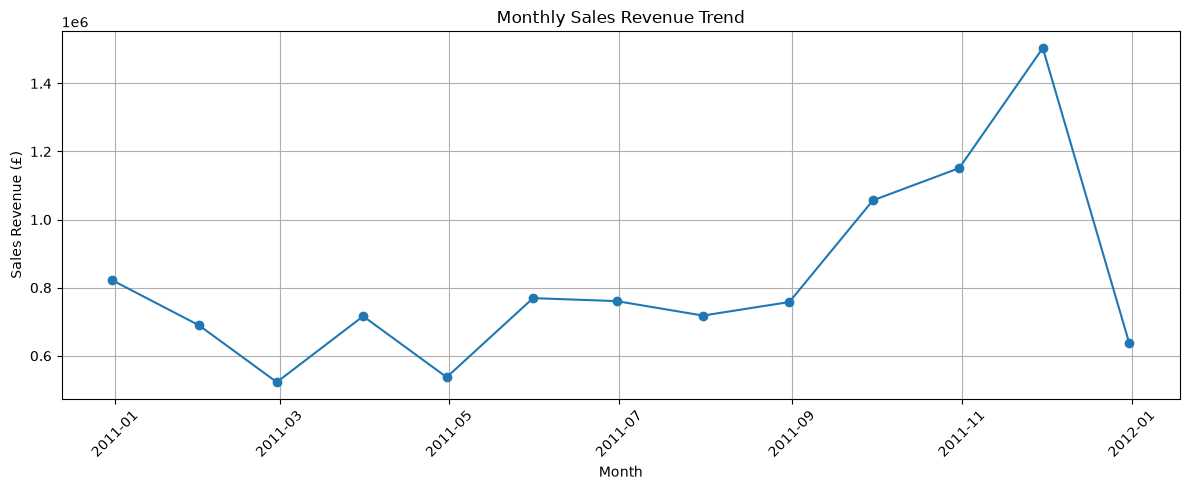

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Sales Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
top_products = (
    df.groupby("Description")["TotalSales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print("Top 10 Products by Revenue:")
print(top_products)

Top 10 Products by Revenue:
Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: TotalSales, dtype: float64


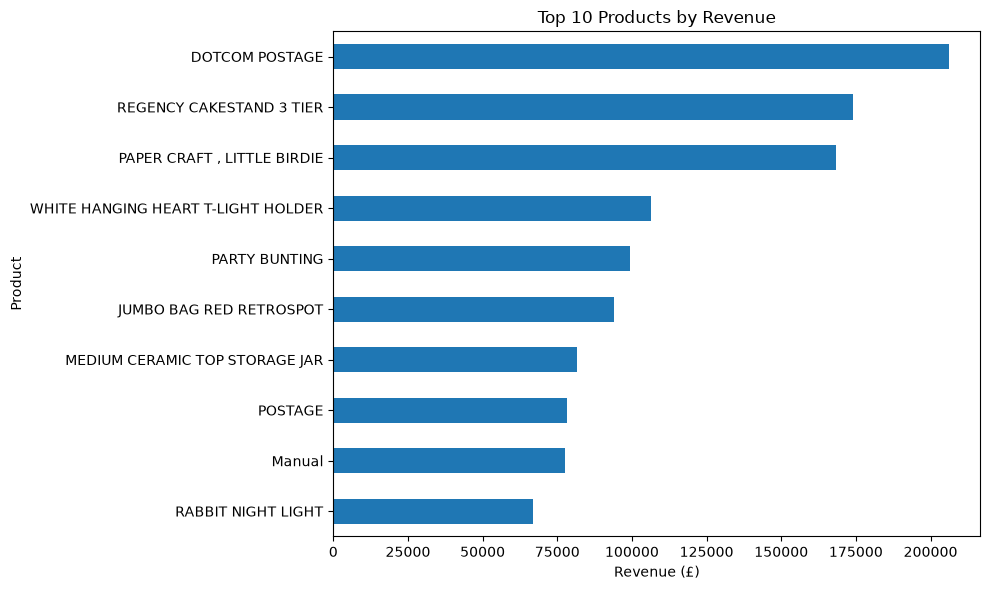

In [11]:
plt.figure(figsize=(10, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [12]:
# Exclude non-merchandise/service entries
product_sales = df[
    ~df["Description"].str.contains(
        "POSTAGE|Manual", case=False, na=False
    )
]

top_merchandise = (
    product_sales.groupby("Description")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Merchandise Products by Revenue:")
print(top_merchandise)

Top 10 Merchandise Products by Revenue:
Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: TotalSales, dtype: float64


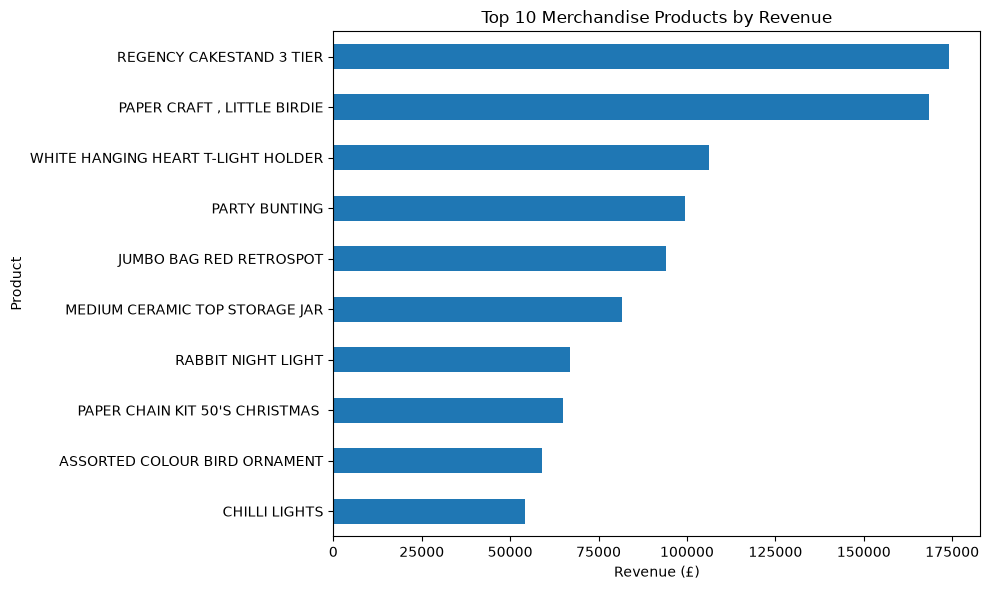

In [13]:
plt.figure(figsize=(10, 6))

top_merchandise.sort_values().plot(kind="barh")

plt.title("Top 10 Merchandise Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [14]:
country_sales = (
    df.groupby("Country")["TotalSales"]
      .sum()
      .sort_values(ascending=False)
)

print("Top 15 Countries by Revenue:")
print(country_sales.head(15))

Top 15 Countries by Revenue:
Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Japan               37416.370
Norway              36165.440
Portugal            33683.050
Finland             22546.080
Singapore           21279.290
Name: TotalSales, dtype: float64


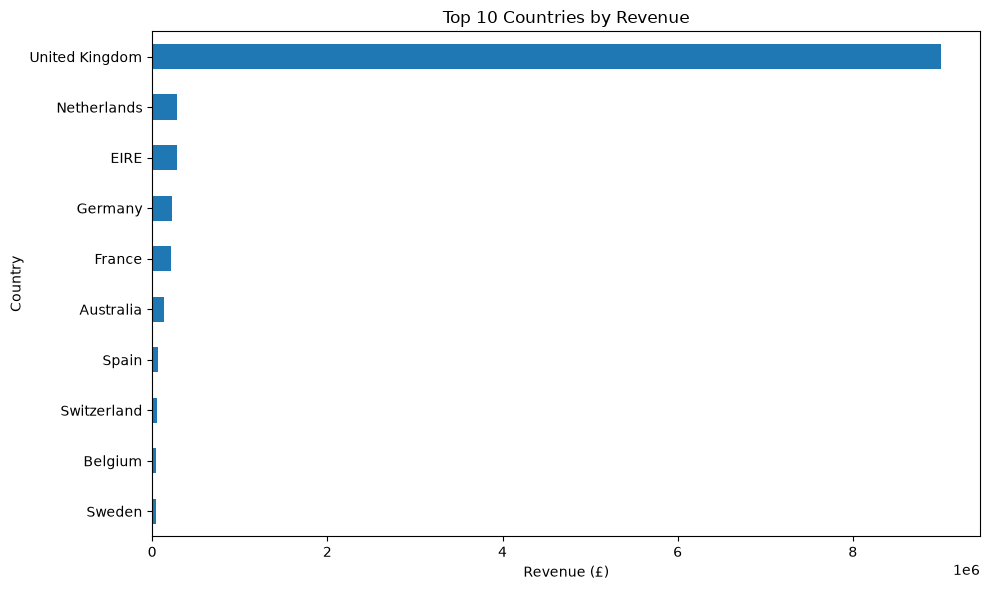

In [15]:
top_countries = country_sales.head(10)

plt.figure(figsize=(10, 6))

top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [16]:
uk_revenue_share = (
    country_sales["United Kingdom"] / df["TotalSales"].sum()
) * 100

top_5_revenue_share = (
    country_sales.head(5).sum() / df["TotalSales"].sum()
) * 100

print(f"United Kingdom revenue share: {uk_revenue_share:.2f}%")
print(f"Top 5 countries revenue share: {top_5_revenue_share:.2f}%")

United Kingdom revenue share: 84.59%
Top 5 countries revenue share: 94.05%


In [17]:
customer_data = df.dropna(subset=["CustomerID"]).copy()

customer_sales = (
    customer_data.groupby("CustomerID")["TotalSales"]
    .agg(
        TotalSpend="sum",
        NumberOfOrders="nunique",
        TotalItems="sum"
    )
    .sort_values("TotalSpend", ascending=False)
)

print("Top 10 Customers by Total Spend:")
print(customer_sales.head(10))

Top 10 Customers by Total Spend:
            TotalSpend  NumberOfOrders  TotalItems
CustomerID                                        
14646.0      280206.02             379   280206.02
18102.0      259657.30             251   259657.30
17450.0      194390.79             202   194390.79
16446.0      168472.50               3   168472.50
14911.0      143711.17             391   143711.17
12415.0      124914.53             247   124914.53
14156.0      117210.08             349   117210.08
17511.0       91062.38             222    91062.38
16029.0       80850.84              80    80850.84
12346.0       77183.60               1    77183.60


In [18]:
customer_sales = (
    customer_data.groupby("CustomerID")
    .agg(
        TotalSpend=("TotalSales", "sum"),
        NumberOfOrders=("InvoiceNo", "nunique"),
        TotalItems=("Quantity", "sum")
    )
    .sort_values("TotalSpend", ascending=False)
)

print("Top 10 Customers by Total Spend:")
print(customer_sales.head(10))

Top 10 Customers by Total Spend:
            TotalSpend  NumberOfOrders  TotalItems
CustomerID                                        
14646.0      280206.02              73      196915
18102.0      259657.30              60       64124
17450.0      194390.79              46       69973
16446.0      168472.50               2       80997
14911.0      143711.17             201       80240
12415.0      124914.53              21       77374
14156.0      117210.08              55       57768
17511.0       91062.38              31       64549
16029.0       80850.84              63       40108
12346.0       77183.60               1       74215


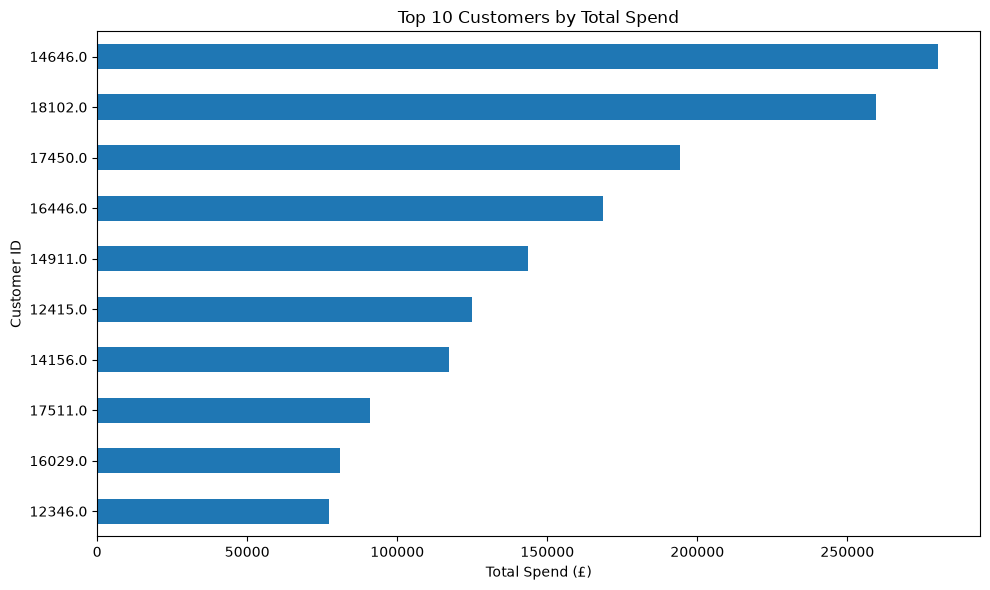

In [19]:
top_customers = customer_sales.head(10)

plt.figure(figsize=(10, 6))

top_customers["TotalSpend"].sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Total Spend")
plt.xlabel("Total Spend (£)")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

In [20]:
# Set the reference date as one day after the last transaction
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = customer_data.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalSales", "sum")
)

print("RFM Customer Data:")
print(rfm.head())

RFM Customer Data:
            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40


In [21]:
# Create quartile-based RFM scores
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

# Combined RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"] +
    rfm["F_Score"] +
    rfm["M_Score"]
)

print(rfm.head(10))

            Recency  Frequency  Monetary  R_Score  F_Score  M_Score  RFM_Score
CustomerID                                                                    
12346.0         326          1  77183.60        1        1        4          6
12347.0           2          7   4310.00        4        4        4         12
12348.0          75          4   1797.24        2        3        4          9
12349.0          19          1   1757.55        3        1        4          8
12350.0         310          1    334.40        1        1        2          4
12352.0          36          8   2506.04        3        4        4         11
12353.0         204          1     89.00        1        1        1          3
12354.0         232          1   1079.40        1        1        3          5
12355.0         214          1    459.40        1        1        2          4
12356.0          23          3   2811.43        3        3        4         10


In [22]:
def segment_customer(score):
    if score >= 10:
        return "High Value"
    elif score >= 7:
        return "Medium Value"
    else:
        return "Low Value"

rfm["Segment"] = rfm["RFM_Score"].apply(segment_customer)

segment_counts = rfm["Segment"].value_counts()

print("Customer Segments:")
print(segment_counts)

Customer Segments:
Segment
Low Value       1807
Medium Value    1271
High Value      1260
Name: count, dtype: int64


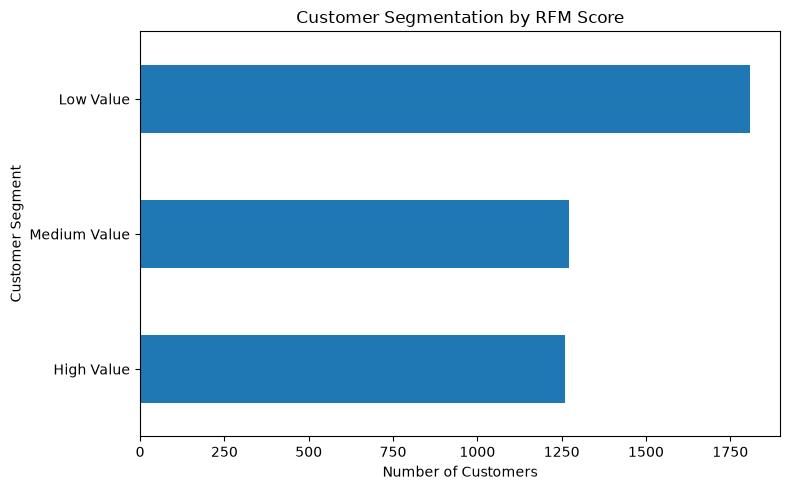

In [23]:
plt.figure(figsize=(8, 5))

segment_counts.sort_values().plot(kind="barh")

plt.title("Customer Segmentation by RFM Score")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

In [24]:
top_quantity_products = (
    product_sales.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Quantity Sold:")
print(top_quantity_products)

Top 10 Products by Quantity Sold:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


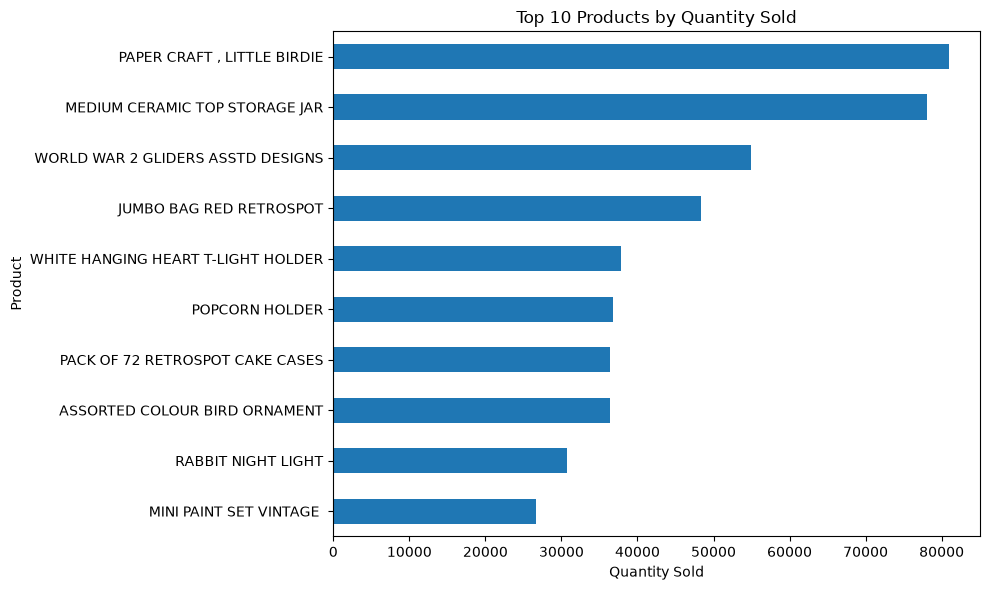

In [25]:
plt.figure(figsize=(10, 6))

top_quantity_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [26]:
daily_sales = (
    df.set_index("InvoiceDate")
      .resample("D")["TotalSales"]
      .sum()
)

rolling_7day = daily_sales.rolling(window=7).mean()

print("7-Day Moving Average:")
print(rolling_7day.dropna().head(10))

7-Day Moving Average:
InvoiceDate
2010-12-07    48406.781429
2010-12-08    46472.291429
2010-12-09    47317.830000
2010-12-10    49049.600000
2010-12-11    49049.600000
2010-12-12    47015.460000
2010-12-13    44632.348571
2010-12-14    36862.878571
2010-12-15    34741.308571
2010-12-16    34107.872857
Freq: D, Name: TotalSales, dtype: float64


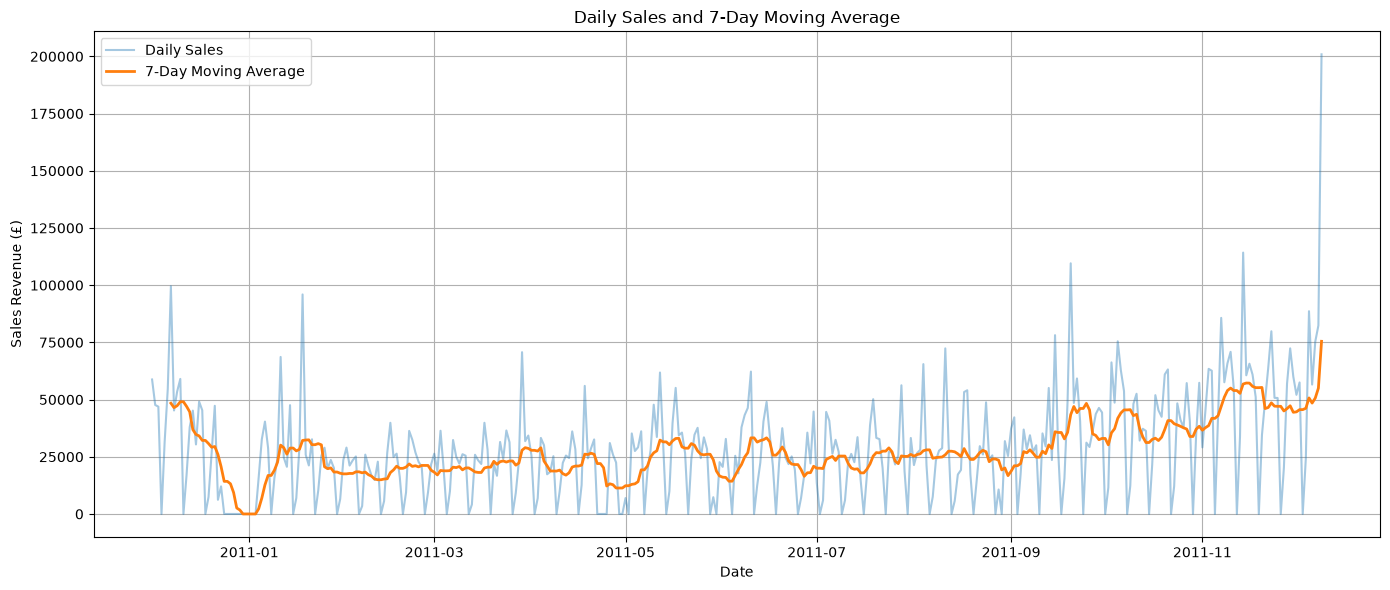

In [27]:
plt.figure(figsize=(14, 6))

plt.plot(daily_sales.index, daily_sales.values, alpha=0.4, label="Daily Sales")
plt.plot(rolling_7day.index, rolling_7day.values, linewidth=2, label="7-Day Moving Average")

plt.title("Daily Sales and 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Sales Revenue (£)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [28]:
monthly_share = (monthly_sales / monthly_sales.sum()) * 100

print("Monthly Revenue Share:")
print(monthly_share.round(2))

Monthly Revenue Share:
InvoiceDate
2010-12-31     7.72
2011-01-31     6.48
2011-02-28     4.91
2011-03-31     6.73
2011-04-30     5.05
2011-05-31     7.23
2011-06-30     7.15
2011-07-31     6.75
2011-08-31     7.12
2011-09-30     9.93
2011-10-31    10.82
2011-11-30    14.13
2011-12-31     5.99
Freq: ME, Name: TotalSales, dtype: float64


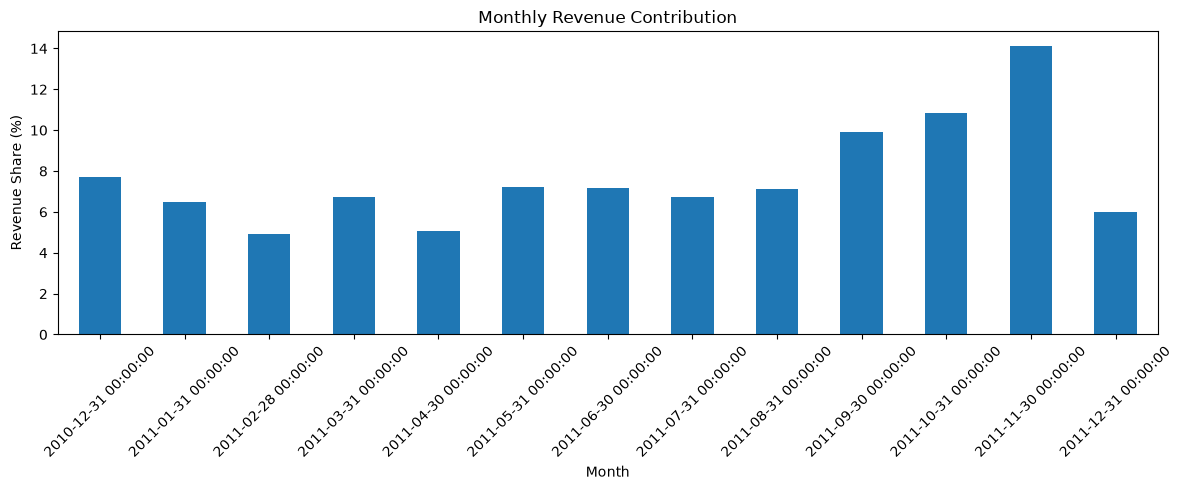

In [29]:
plt.figure(figsize=(12, 5))

monthly_share.plot(kind="bar")

plt.title("Monthly Revenue Contribution")
plt.xlabel("Month")
plt.ylabel("Revenue Share (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

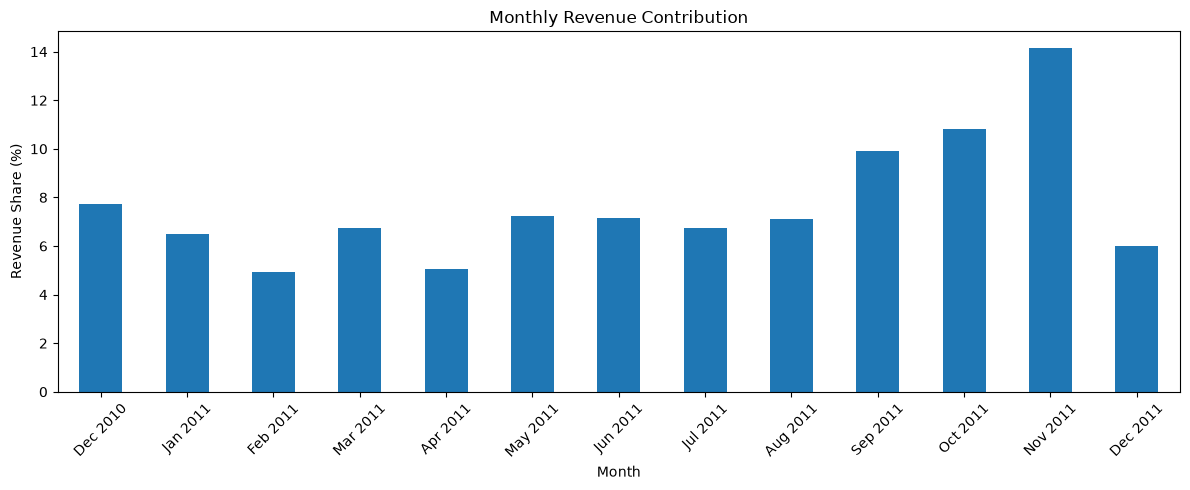

In [30]:
monthly_share_clean = monthly_share.copy()
monthly_share_clean.index = monthly_share_clean.index.strftime("%b %Y")

plt.figure(figsize=(12, 5))

monthly_share_clean.plot(kind="bar")

plt.title("Monthly Revenue Contribution")
plt.xlabel("Month")
plt.ylabel("Revenue Share (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [31]:
segment_revenue = rfm.groupby("Segment")["Monetary"].sum().sort_values(ascending=False)

segment_revenue_share = (segment_revenue / segment_revenue.sum() * 100).round(2)

print("Revenue by Customer Segment:")
print(segment_revenue)

print("\nRevenue Share by Customer Segment (%):")
print(segment_revenue_share)

Revenue by Customer Segment:
Segment
High Value      6819332.770
Medium Value    1372734.143
Low Value        695141.981
Name: Monetary, dtype: float64

Revenue Share by Customer Segment (%):
Segment
High Value      76.73
Medium Value    15.45
Low Value        7.82
Name: Monetary, dtype: float64


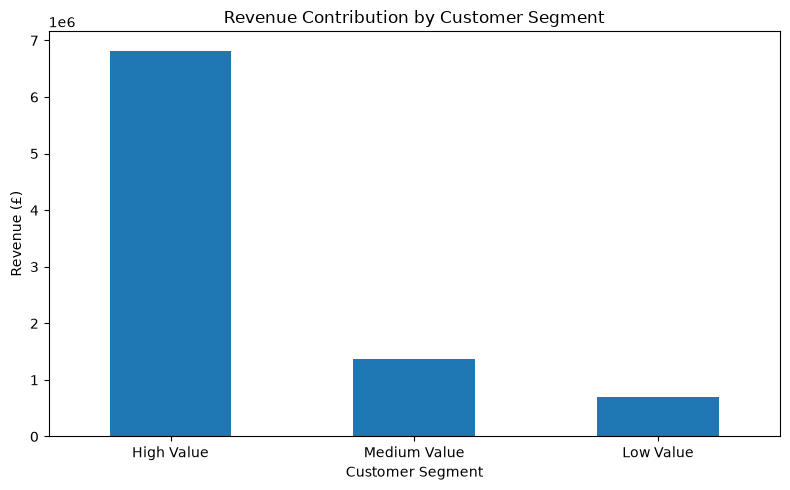

In [32]:
plt.figure(figsize=(8, 5))

segment_revenue.plot(kind="bar")

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## Business Insights

The analysis of the retail transaction dataset produced several important business insights:

### 1. Strong Overall Revenue Performance
The cleaned dataset generated total sales revenue of approximately **£10.64 million** across **19,960 transactions**, covering **3,922 products** and **38 countries**.

### 2. Strong Seasonal Pattern
Revenue increased significantly during the second half of 2011. November 2011 was the strongest month, contributing approximately **14.13% of total annual revenue**.

September, October, and November together contributed more than one-third of total revenue, indicating a strong seasonal demand pattern toward the end of the year.

### 3. United Kingdom Dominates Revenue
The United Kingdom generated approximately **84.59% of total revenue**. The top five countries together contributed approximately **94.05%** of revenue.

This indicates that the business is highly concentrated in a small number of markets.

### 4. High-Value Customers Drive Revenue
The customer segmentation analysis showed:

- High Value customers: **1,260 customers**
- Medium Value customers: **1,271 customers**
- Low Value customers: **1,807 customers**

Despite representing a smaller portion of the customer base, High Value customers generated approximately **76.73% of total customer revenue**.

### 5. Product Demand is Concentrated
"Paper Craft, Little Birdie" was the highest-selling product by quantity, with more than **80,000 units sold**.

"Regency Cake Stand 3 Tier" was the highest-revenue merchandise product, generating approximately **£174,157**.

### 6. Customer Recency and Frequency Matter
The RFM analysis showed substantial differences in customer purchasing behaviour. Some customers made frequent purchases and generated high monetary value, while others purchased only once or had not purchased recently.

This provides an opportunity to develop targeted customer retention strategies.

### 7. Business Recommendations

Based on the analysis, the following actions are recommended:

- Prioritize retention programs for High Value customers.
- Offer personalized promotions to Medium Value customers to increase their spending and frequency.
- Use targeted re-engagement campaigns for Low Value or inactive customers.
- Increase inventory and marketing efforts before the strong September-November demand period.
- Investigate opportunities to expand sales outside the United Kingdom to reduce geographic concentration.
- Maintain sufficient stock of high-volume products such as Paper Craft, Little Birdie and Medium Ceramic Top Storage Jar.
- Use customer purchasing behaviour to create personalized product recommendations and promotional campaigns.

## Conclusion

This project demonstrated an end-to-end retail analytics workflow using real-world transaction data.

The analysis covered data loading, data cleaning, revenue calculation, product performance, geographic performance, customer analysis, sales trends, moving averages, revenue contribution, and RFM-based customer segmentation.

The results show that the business generated approximately **£10.64 million in revenue**, with strong seasonal growth toward the end of the year. Revenue is heavily concentrated in the United Kingdom, while a relatively small group of High Value customers contributes the majority of customer revenue.

The analysis demonstrates how transaction-level retail data can be transformed into actionable business insights. These insights can support decisions related to inventory planning, customer retention, marketing campaigns, product strategy, and geographic expansion.